In [1]:
import numpy as np
from itertools import combinations_with_replacement
from math import gcd
from functools import reduce
from collections import Counter
from scipy.special import factorial
import pickle

from scipy.optimize import minimize, minimize_scalar,shgo
from numpy.polynomial.polynomial import Polynomial

from tqdm import tqdm

import qutip as qt

import matplotlib.pyplot as plt

In [2]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)

In [3]:
Ns=100

a = qt.destroy(Ns)

def th_dm_th(Ns,mu):
    return qt.thermal_dm(Ns,mu)

def th_dm_co(Ns,mu):
    return qt.coherent_dm(Ns, mu)

def fs(Ns,n):
    return qt.states.fock(Ns,n)

def state_dm_th(Ns,mu,p,nad=1):
    st = (p*a.dag()*th_dm_th(Ns,mu)*a + (1-p)*th_dm_th(Ns,mu))
    if nad > 1:
        for i in range(nad-1):
            st = (p*a.dag()*st*a + (1-p)*st)
    st = st.unit()
    return st

def state_dm_co(Ns,mu,p,nad=1):
    st = (p*a.dag()*th_dm_co(Ns,mu)*a + (1-p)*th_dm_co(Ns,mu))
    if nad > 1:
        for i in range(nad-1):
            st = (p*a.dag()*st*a + (1-p)*st)
    st = st.unit()
    return st


def state_dm_pba_bacs(Ns,alpha,p,l,nad=1):
    rho = state_bacs(Ns,alpha,l)*state_bacs(Ns,alpha,l).dag()
    rho =  p*a.dag()*rho*a + (1-p)*rho
    for i in range(nad-1):
         rho = (p*a.dag()*rho*a + (1-p)*rho)
            
    rho = rho.unit()
    return rho

def state_dm_pba_co(Ns,alpha,p,nad=1):
    #cst = qt.coherent(Ns,alpha)
    rho = qt.coherent_dm(Ns,alpha)
    rho =  p*(a.dag()*rho*a).unit() + (1-p)*rho
    for i in range(nad-1):
        rho = (p*(a.dag()*rho*a).unit() + (1-p)*rho)

            
    rho = rho.unit()
    return rho

def state_dm_pba_co_2_3(Ns,alpha,p,nad=1):
    #cst = qt.coherent(Ns,alpha)
    rho = qt.coherent_dm(Ns,alpha)
    rho =  p*(a.dag()*a.dag()*a.dag()*rho*a*a*a).unit() + (1-p)*(a.dag()*a.dag()*rho*a*a).unit()
    #for i in range(nad-1):
    #    rho = (p*(a.dag()*rho*a).unit() + (1-p)*rho)

            
    rho = rho.unit()
    return rho

def state_dm_pba_co_2_0(Ns,alpha,p,nad=1):
    #cst = qt.coherent(Ns,alpha)
    rho = qt.coherent_dm(Ns,alpha)
    rho =  p*(a.dag()*a.dag()*rho*a*a).unit() + (1-p)*(a.dag()*rho*a).unit()

    rho = rho.unit()
    return rho


def test_P_pba(mu,p,l,k):
    return (np.exp(-mu)/factorial(k))*((mu**(k-1)*p*k**2/(mu+1))+(1-p)*mu**k)


def pba_Pk_bacs(Ns,mu,p,l,k,nad=1):
    alpha=np.sqrt(mu)
    st = state_dm_pba_bacs(Ns,alpha,p,l,nad=nad)
    Pk = (fs(Ns,k).dag()*st*fs(Ns,k))
    return np.real(Pk)

def pba_Pk_co(Ns,mu,p,k,nad=1):
    alpha=np.sqrt(mu)
    st = state_dm_pba_co(Ns,alpha,p,nad=nad)
    Pk = (fs(Ns,k).dag()*st*fs(Ns,k))
    return np.real(Pk)

def pba_Pk_co_2_3(Ns,mu,p,k,nad=1):
    alpha=mu/np.sqrt(2)#This is not tested, it is a guess
    st = state_dm_pba_co_2_3(Ns,alpha,p,nad=nad)
    Pk = (fs(Ns,k).dag()*st*fs(Ns,k))
    return np.real(Pk)

def pba_Pk_co_2_0(Ns,mu,p,k,nad=1):
    alpha=mu/np.sqrt(2)#This is not tested, it is a guess
    st = state_dm_pba_co_2_0(Ns,alpha,p,nad=nad)
    Pk = (fs(Ns,k).dag()*st*fs(Ns,k))
    return np.real(Pk)

In [4]:
def generate_arrays(N,M,indx=np.array([0,1,2,3],dtype=int)):
    result = []
    for comb in combinations_with_replacement(indx, N):
        if sum(comb) == M:
            sorted_comb = tuple(sorted(comb, reverse=True))
            result.append(sorted_comb)
    return np.array(result)

def majorization_rule(array1, array2):
    return np.all(np.cumsum(array1) >= np.cumsum(array2))

def generate_majorization_pairs(arrays):
    pairs = []
    for i in range(len(arrays)):
        for j in range(len(arrays)):
            if majorization_rule(arrays[i], arrays[j]):
                pairs.append((arrays[i], arrays[j]))
    return pairs

def filter_non_overlapping_pairs(pairs):
    filtered_pairs = []
    
    for pair in pairs:
        array1, array2 = set(pair[0]), set(pair[1])
        if array1.isdisjoint(array2):
            filtered_pairs.append(pair)
    
    return filtered_pairs

def gcd_of_list(lst):
    return reduce(gcd, lst)

def multiplicities_gcd(array):
    counts = Counter(array)
    gcd_value = gcd_of_list(list(counts.values()))
    return gcd_value

def filter_pairs_with_common_factors(pairs):
    final_pairs = []
    
    for pair in pairs:
        aux = np.append(pair[0], pair[1])
        gcd = multiplicities_gcd(aux)
        
        if gcd == 1:
            final_pairs.append(pair)
    
    return final_pairs


def all_pairs_for_list_of_P(indx=np.array([0,1,2,3])):
    
    M=np.sum(range(np.max(indx)+1),dtype=int)
    N=M
    
    all_p=[]
    for i in range(N+1):
        for j in range(1,M+1):
            arrays = generate_arrays(i, j,indx=indx)
            pairs = generate_majorization_pairs(arrays)
            pairs_aux = filter_non_overlapping_pairs(pairs)
            pairs_aux2 = filter_pairs_with_common_factors(pairs_aux)
            for pair in pairs_aux2:
                all_p.append(pair)              
    return all_p

In [5]:
#Eq. (28)

def test_P_pba(mu,p,l,k):
    return (np.exp(-mu)/factorial(k))*((mu**(k-1)*p*k**2/(mu+1))+(1-p)*mu**k)


#Eq (28)+(26b) 
def test_P_pba_v2(mu,p,l,k):
    return (np.exp(-mu)/factorial(k))*((mu**(k-2)*p*(k*(k-1))**2/(mu**2+4*mu+2))+(1-p)*mu**k)


#Eq.(31)
def thermFS_pba(mu,p,l,k):
    return ((1-p)*k*mu**(k-1)+p*mu**k)/(1+mu)**(k+1)



Be carefull here, all_pairs_for_list_of_P returns pairs of probability tuples $T^{(0),(1)}$ for which $T^{(0)} \succcurlyeq T^{(1)}$, consequantly the Generalized Klyshko inequalities are:

\begin{equation}
\prod_{i=1}^sT^{(1)}_i! P_{T^{(1)}_i} \leq \prod_{i=1}^sT^{(0)}_i! P_{T^{(0)}_i}
\end{equation}

In [6]:
def generalized_klyshko(Pall=np.ones((10,10,3)),indx=np.array([0,1,2],dtype=int)):
        
            
    Psh = Pall.shape
    
    NP = Psh[-1]
    if (NP != len(indx)):
        print("The array of probabilities and the index of probailities are different!")
        exit(0)
    
    rev_index=np.zeros((np.max(indx)+1),dtype=int)
    for i in range(NP):
        rev_index[indx[i]]=i
    
    nonclass = np.zeros((Psh[0],Psh[1]), dtype=bool)
    
    all_pairs = all_pairs_for_list_of_P(indx=indx) 
    

    for pair in all_pairs:
        
        fact0 = factorial(pair[0])
        fact1 = factorial(pair[1])
        fact = np.prod(fact0/fact1)

        
        Paux0 = fact*np.ones((Psh[0],Psh[1]))
        Paux1 = np.ones((Psh[0],Psh[1]))
         
        for i in pair[1]:
            Paux1 *= Pall[:,:,rev_index[i]]
            
        for i in pair[0]:
            Paux0 *= Pall[:,:,rev_index[i]]
            
        Paux = Paux1 - Paux0
    
        nonclass = np.where(Paux > 0,True,nonclass)
        
    ncaf = np.sum(nonclass.astype(int))/(Psh[0]*Psh[1])
    return nonclass,ncaf,len(all_pairs)

In [7]:
list_of_files=["all_genK/genKlyshko_up_to3.pkl",
               "all_genK/genKlyshko_up_to4.pkl",
               "all_genK/genKlyshko_up_to5.pkl",
               "all_genK/genKlyshko_up_to6.pkl",
               "all_genK/genKlyshko_up_to7.pkl",
               "all_genK/genKlyshko_up_to8.pkl"]



The same as above, but I am loading the tuples from a file

In [8]:
def generalized_klyshko_first_Np(Pall=np.ones((10,10,3)),lof=list_of_files):
        
            
    Psh = Pall.shape
    
    NP = Psh[-1]
    
    indx=np.arange(0,NP,1,dtype=int)
    print(indx)
    
    rev_index=np.zeros((np.max(indx)+1),dtype=int)
    for i in range(NP):
        rev_index[indx[i]]=i
    
    nonclass = np.zeros((Psh[0],Psh[1]), dtype=bool)
    
    
    with open(lof[NP-4], 'rb') as f:
        all_pairs = pickle.load(f)

    for pair in all_pairs:
        
        fact0 = factorial(pair[0])
        fact1 = factorial(pair[1])
        fact = np.prod(fact0/fact1)

        
        Paux0 = fact*np.ones((Psh[0],Psh[1]))
        Paux1 = np.ones((Psh[0],Psh[1]))
         
        for i in pair[1]:
            Paux1 *= Pall[:,:,rev_index[i]]
            
        for i in pair[0]:
            Paux0 *= Pall[:,:,rev_index[i]]
            
        Paux = Paux1 - Paux0
    
        nonclass = np.where(Paux > 0,True,nonclass)
        
    ncaf = np.sum(nonclass.astype(int))/(Psh[0]*Psh[1])
    return nonclass,ncaf,len(all_pairs)

In [9]:
def generalized_klyshko_first_Np_ch(Pall=np.ones((10,10,3)),lof=list_of_files,ipair=np.array([1,2,3])):
        
            
    Psh = Pall.shape
    
    NP = Psh[-1]
    
    indx=np.arange(0,NP,1,dtype=int)
    print(indx)
    
    rev_index=np.zeros((np.max(indx)+1),dtype=int)
    for i in range(NP):
        rev_index[indx[i]]=i
    
    nonclass = np.zeros((Psh[0],Psh[1]), dtype=bool)
    
    
    with open(lof[NP-4], 'rb') as f:
        all_pairs = pickle.load(f)

    
    for i0 in ipair:
        
        pair = all_pairs[i0]
        fact0 = factorial(pair[0])
        fact1 = factorial(pair[1])
        fact = np.prod(fact0/fact1)

        
        Paux0 = fact*np.ones((Psh[0],Psh[1]))
        Paux1 = np.ones((Psh[0],Psh[1]))
         
        for i in pair[1]:
            Paux1 *= Pall[:,:,rev_index[i]]
            
        for i in pair[0]:
            Paux0 *= Pall[:,:,rev_index[i]]
            
        Paux = Paux1 - Paux0
    
        nonclass = np.where(Paux > 0,True,nonclass)
        
    ncaf = np.sum(nonclass.astype(int))/(Psh[0]*Psh[1])
    return nonclass,ncaf,len(all_pairs)

Standard Klyshko:
\begin{equation}
  k P_k^2 \leq (k+1)P_{k-1}P_{k+1}
\end{equation}

In [10]:
def klyshko(Pall=np.ones((10,10,3))):

    Psh = Pall.shape
    Ns = np.array(np.prod(Psh[0:-1]))
    
    NP = Psh[-1]
    Nm = NP-1
    
    
    nonclass = np.zeros((Psh[0],Psh[1]), dtype=bool)
    
    

    for i1 in range(1,Nm):
        Paux = (i1+1)*Pall[:,:,i1-1]*Pall[:,:,i1+1]-i1*Pall[:,:,i1]**2
        nonclass = np.where(Paux < 0,True,nonclass)
    
        
    ncaf = np.sum(nonclass.astype(int))/Ns
    return nonclass,ncaf

${\cal K}_{\infty,N_P}$


In [19]:
def taylored(Pall=np.ones((10,10,3))):

    Psh = Pall.shape
    Ns = np.array(np.prod(Psh[0:-1]))
    
    NP = Psh[-1]
    Nm = NP-1
    
    
    nonclass = np.zeros((Psh[0],Psh[1]), dtype=bool)
    
    SumA = np.zeros((Psh[0],Psh[1],NP))
    SumB = np.zeros((Psh[0],Psh[1]))

    
    SumA[:,:,0] = Pall[:,:,0]
    
    
    for i1 in range(1,Nm):    
        SumA[:,:,i1]=SumA[:,:,i1-1]+Pall[:,:,i1]


    for nn in range(2,Nm+1):
    
        SumB[:,:] = 1.0
        for k in range(1,nn-1):
            SumB += ((nn*Pall[:,:,nn]/Pall[:,:,nn-1])**k)/factorial(k)        
        
        Paux = nn*Pall[:,:,nn]
        Paux -= Pall[:,:,nn-1]*np.log((nn**nn/factorial(nn))*
                                     ((Pall[:,:,nn]**(nn-1))/(Pall[:,:,nn-1]**nn))*
                                     (1.0-SumA[:,:,nn-2]) + SumB)
        
        nonclass = np.where(Paux > 0,True,nonclass)
        
    ncaf = np.sum(nonclass.astype(int))/Ns
    return nonclass,ncaf

In [20]:
def log01rule(Pall=np.ones((10,10,3))):
    Psh = Pall.shape    
    nonclass = np.zeros((Psh[0],Psh[1]), dtype=bool)
    
    Paux = Pall[:,:,1]+Pall[:,:,0]*np.log(Pall[:,:,0])
    nonclass = np.where(Paux > 0,True,nonclass)
    ncaf = np.sum(nonclass.astype(int))/(Psh[0]*Psh[1])
    return nonclass,ncaf

In [25]:
%%time

Np = 512
Nmu = 512

p_all= np.linspace(0.0001, 0.9999, num=Np, endpoint=True)
mu_all = np.linspace(0.0001, 20.0, num=Nmu, endpoint=True)

NP = 4
#fi="../Data/All_analytical/BosonAdded_1/all_an_pba1_Np8.npy"

idx=np.arange(0,NP,1,dtype=int)
print(idx)
Nadd = 1
pps="5, Nadd =1"


noise_on = True

Pall=np.zeros((Np,Nmu,NP))

for ip in range(Np):
    for imu in range(Nmu):
        for iP in range(NP):
            Pall[ip,imu,iP] = test_P_pba(mu_all[imu],p_all[ip],2,iP)
            #Pall[ip,imu,iP] =  thermFS_pba(mu_all[imu],p_all[ip],1,iP)
            

[0 1 2 3]
CPU times: user 4.16 s, sys: 2 μs, total: 4.16 s
Wall time: 4.16 s


In [26]:
#ac_gkl,ac_gkl_frac,ac_gkl_n = generalized_klyshko(Pall=Pall,indx=idx)

ac_gkl,ac_gkl_frac,ac_gkl_n = generalized_klyshko_first_Np(Pall=Pall,lof=list_of_files)
print("GKL:",ac_gkl_frac)

ac_kl,ac_kl_frac = klyshko(Pall=Pall)
print("KL:",ac_kl_frac)

ac_tay,ac_tay_frac = taylored(Pall=Pall)
print("Kinf:",ac_tay_frac)

ac_log,ac_log_frac = log01rule(Pall=Pall)

print("LB:",ac_log_frac)

#with open(fi, 'wb') as f:
#    np.save(f,mu_all)
#    np.save(f,p_all)
#    np.save(f,ac_gkl)
#    np.save(f,ac_gkl_frac)
#    np.save(f,ac_gkl_n)
#    np.save(f,ac_kl)
#    np.save(f,ac_kl_frac)    
#    np.save(f,ac_tay)
#    np.save(f,ac_tay_frac)
#    np.save(f,ac_log)
#    np.save(f,ac_log_frac)  
    


[0 1 2 3]
GKL: 0.11911773681640625
KL: 0.11911773681640625
Kinf: 0.25897216796875
LB: 0.06745147705078125


Text(0.5, 1.0, 'Taylored-Log01Rule')

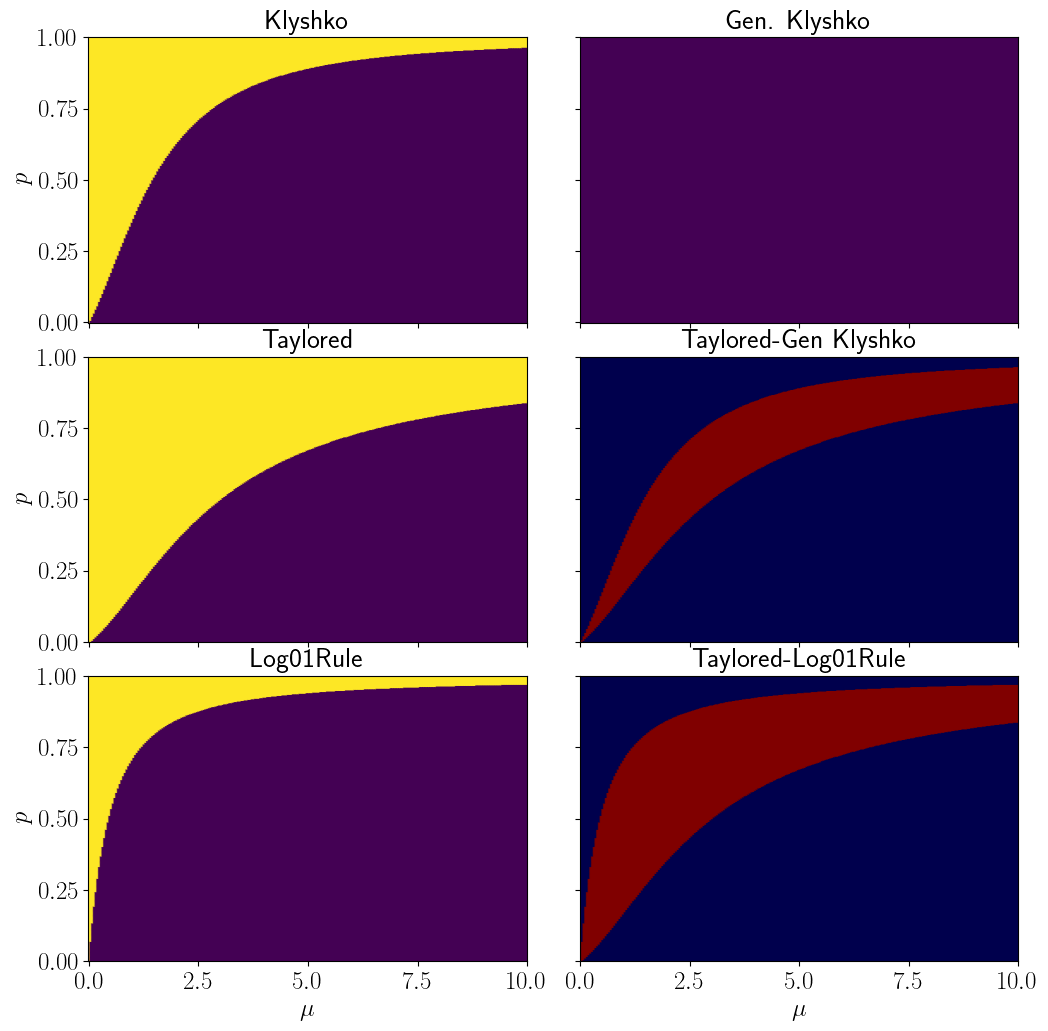

In [28]:
plt.rcParams['text.usetex'] = True
plt.rcParams.update({'font.size':18})

ncols=2
nrows=3

xmu, yp = np.meshgrid(mu_all, p_all)

fig, axs = plt.subplots(ncols=ncols, nrows=nrows,figsize=(12, 12),sharex='all', sharey='all')
plt.subplots_adjust(wspace=0.12, hspace=0.12)

levels=[0.0,1.0,2.0]
colors=['red','blue','black']
siz = 3.0

images = []
for ic in range(ncols):
    for ir in range(nrows):
        axs[ir,ic].set_xlim([-0.01,10])
        axs[ir,ic].set_ylim([-0.001,1])
#        axs[ic,ir].set_xticks([0,2,4,6,8,10])
#        axs[ic,ir].set_yticks([0,0.2,0.4,0.6,0.8,1])

axs[2,0].set_xlabel(r"$\mu$")
axs[2,1].set_xlabel(r"$\mu$")
axs[0,0].set_ylabel(r"$p$")
axs[1,0].set_ylabel(r"$p$")
axs[2,0].set_ylabel(r"$p$")
        
i=0

#col=axs[0].contourf(xmu, yp, nc_a_jj)
axs[0,0].scatter(xmu, yp, c=ac_kl,s=siz,marker="o")
axs[0,0].set_title(r'Klyshko',fontsize=20)

#col=axs[1].contourf(xmu, yp, nc_kl_jj)
axs[0,1].scatter(xmu, yp, c=ac_gkl,s=siz,marker="o")
axs[0,1].set_title(r'Gen. Klyshko',fontsize=20)


#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[1,0].scatter(xmu, yp, c=ac_tay,s=siz,marker="o")
axs[1,0].set_title(r'Taylored',fontsize=20)    

#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[1,1].scatter(xmu, yp, c=((ac_tay.astype(int)-ac_kl.astype(int))),s=siz,marker="o",cmap="seismic")
axs[1,1].set_title(r'Taylored-Gen Klyshko',fontsize=20)  

#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[2,0].scatter(xmu, yp, c=ac_log,s=siz,marker="o")
axs[2,0].set_title(r'Log01Rule',fontsize=20)    

#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[2,1].scatter(xmu, yp, c=((ac_tay.astype(int)-ac_log.astype(int))),s=siz,marker="o",cmap="seismic")
axs[2,1].set_title(r'Taylored-Log01Rule',fontsize=20)  

#fig.savefig(fig_file, format="jpg", bbox_inches="tight", dpi=526)

In [59]:
NP = 9
idx=np.arange(0,NP,1,dtype=int)

fi_in="../Data/All_analytical/BosonAdded_2/P_bacs_Np9_Nadd2.npy"
with open(fi_in, 'rb') as f:
    p_all=np.load(f)
    mu_all=np.load(f)
    Pall9=np.load(f)   
    
Np = len(p_all)
Nmu = len(mu_all)
print(Np,Nmu,NP)

Pall = Pall9[:,:,0:NP]

fi_out="../Data/All_analytical/BosonAdded_2/all_an_pba2_Np9.npy"

151 151 9


In [60]:
#ac_gkl,ac_gkl_frac,ac_gkl_n = generalized_klyshko(Pall=Pall,indx=idx)

ac_gkl,ac_gkl_frac,ac_gkl_n = generalized_klyshko_first_Np(Pall=Pall,lof=list_of_files)

ac_kl,ac_kl_frac = klyshko(Pall=Pall)

ac_tay,ac_tay_frac = taylored(Pall=Pall)

ac_log,ac_log_frac = log01rule(Pall=Pall)


with open(fi_out, 'wb') as f:
    np.save(f,mu_all)
    np.save(f,p_all)
    np.save(f,ac_gkl)
    np.save(f,ac_gkl_frac)
    np.save(f,ac_gkl_n)
    np.save(f,ac_kl)
    np.save(f,ac_kl_frac)    
    np.save(f,ac_tay)
    np.save(f,ac_tay_frac)
    np.save(f,ac_log)
    np.save(f,ac_log_frac)   

[0 1 2 3 4 5 6 7 8]


/tmp/ipykernel_1376758/3489667697.py:30: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  Paux -= Pall[:,:,nn-1]*np.log((nn**nn/np.math.factorial(nn))*
/tmp/ipykernel_1376758/3489667697.py:31: RuntimeWarning: divide by zero encountered in divide
  ((Pall[:,:,nn]**(nn-1))/(Pall[:,:,nn-1]**nn))*
/tmp/ipykernel_1376758/3489667697.py:30: RuntimeWarning: invalid value encountered in multiply
  Paux -= Pall[:,:,nn-1]*np.log((nn**nn/np.math.factorial(nn))*
/tmp/ipykernel_1376758/3489667697.py:27: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  SumB += ((nn*Pall[:,:,nn]/Pall[:,:,nn-1])**k)/np.math.factorial(k)
/tmp/ipykernel_1376758/2597303894.py:5: RuntimeWarning: divide by zero encountered in log
  Paux = Pall[:,:,1]+Pall[:,:,0]*np.log(Pall[:,:,0])
/tmp/ipykernel_1376758/25973

# JC

In [109]:
def Pjaycum(n,nu,tau,pe):
    nuf1 = nu**n/(1+nu)**(1+n)
    nuf2 = (1+nu)/nu
    nuf3 = nu/(1+nu)
    resA = (np.cos(tau*np.sqrt(n+1)))**2 + nuf2*(np.sin(tau*np.sqrt(n)))**2
    resB = (np.cos(tau*np.sqrt(n)))**2 + nuf3*(np.sin(tau*np.sqrt(n+1)))**2
    res = nuf1*(pe*resA + (1.0-pe)*resB)
    return res

In [120]:
tau = np.arange(0.01,10.001,0.025)
nu = np.arange(0.01,6.001,0.025)

N_tau = tau.shape[0]
N_nu = nu.shape[0]
N_P = 30

xtau, ynu = np.meshgrid(tau, nu)

Pall = np.empty((N_nu,N_tau,0))
for i1 in range(N_P):
    Paux = Pjaycum(n=i1,nu=ynu,tau=xtau,pe=1.0/3.0)
    Pall = np.append(Pall,Paux[...,np.newaxis],axis=2)

In [121]:
#ac_gkl,ac_gkl_frac,ac_gkl_n = generalized_klyshko(Pall=Pall,indx=idx)

#ac_gkl,ac_gkl_frac,ac_gkl_n = generalized_klyshko_first_Np(Pall=Pall,lof=list_of_files)

ac_kl,ac_kl_frac = klyshko(Pall=Pall)

ac_tay,ac_tay_frac = taylored(Pall=Pall)

ac_log,ac_log_frac = log01rule(Pall=Pall)

/tmp/ipykernel_1376758/3489667697.py:30: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  Paux -= Pall[:,:,nn-1]*np.log((nn**nn/np.math.factorial(nn))*
/tmp/ipykernel_1376758/3489667697.py:27: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  SumB += ((nn*Pall[:,:,nn]/Pall[:,:,nn-1])**k)/np.math.factorial(k)
/tmp/ipykernel_1376758/3489667697.py:30: RuntimeWarning: invalid value encountered in log
  Paux -= Pall[:,:,nn-1]*np.log((nn**nn/np.math.factorial(nn))*
/tmp/ipykernel_1376758/3489667697.py:31: RuntimeWarning: invalid value encountered in divide
  ((Pall[:,:,nn]**(nn-1))/(Pall[:,:,nn-1]**nn))*
/tmp/ipykernel_1376758/3489667697.py:31: RuntimeWarning: divide by zero encountered in divide
  ((Pall[:,:,nn]**(nn-1))/(Pall[:,:,nn-1]**nn))*
/tmp/ipykernel_1376758/3489667697.

UFuncTypeError: Cannot cast ufunc 'add' output from dtype('O') to dtype('float64') with casting rule 'same_kind'

Text(0.5, 1.0, 'Taylored-Log01Rule')

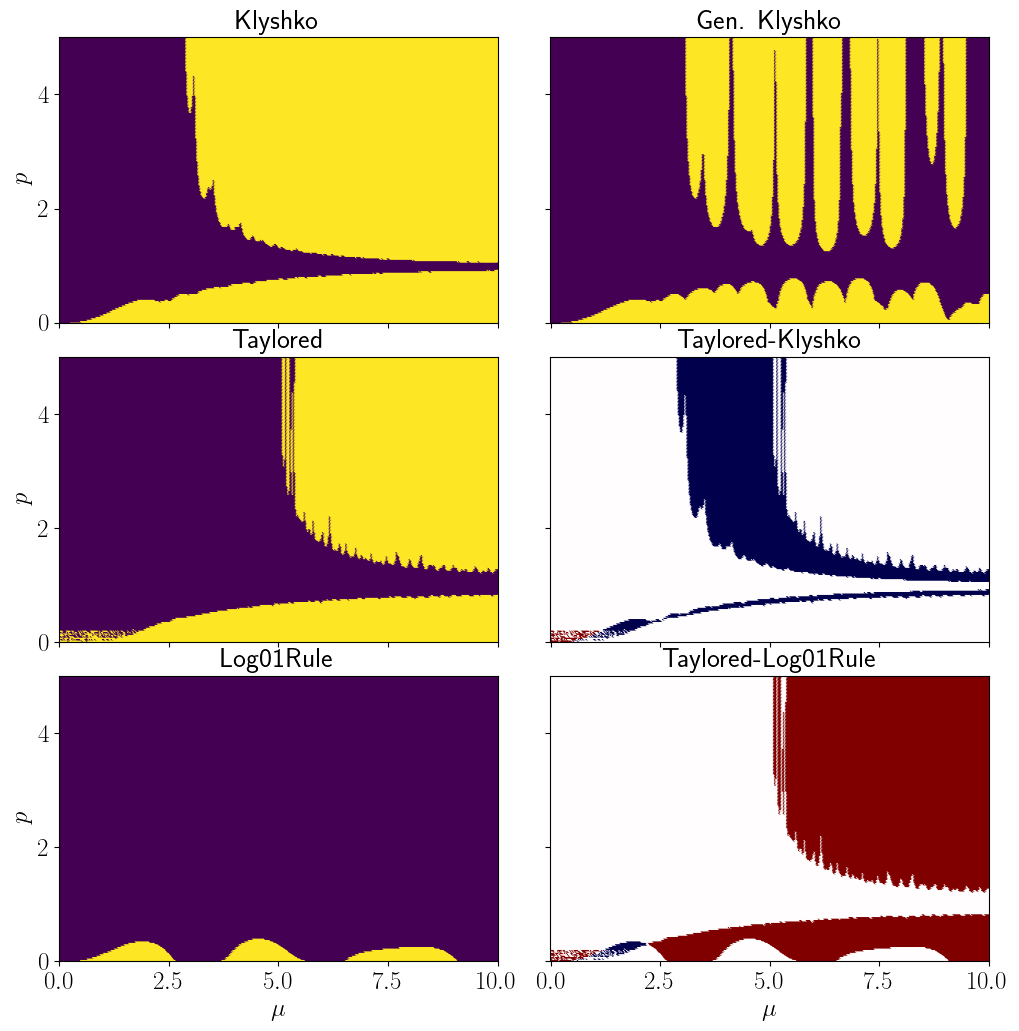

In [123]:
plt.rcParams['text.usetex'] = True
plt.rcParams.update({'font.size':18})

ncols=2
nrows=3


fig, axs = plt.subplots(ncols=ncols, nrows=nrows,figsize=(12, 12),sharex='all', sharey='all')
plt.subplots_adjust(wspace=0.12, hspace=0.12)

levels=[0.0,1.0,2.0]
colors=['red','blue','black']
siz = 3.0

images = []
for ic in range(ncols):
    for ir in range(nrows):
        axs[ir,ic].set_xlim([-0.01,10])
        axs[ir,ic].set_ylim([-0.001,5])
#        axs[ic,ir].set_xticks([0,2,4,6,8,10])
#        axs[ic,ir].set_yticks([0,0.2,0.4,0.6,0.8,1])

axs[2,0].set_xlabel(r"$\mu$")
axs[2,1].set_xlabel(r"$\mu$")
axs[0,0].set_ylabel(r"$p$")
axs[1,0].set_ylabel(r"$p$")
axs[2,0].set_ylabel(r"$p$")
        
i=0

#col=axs[0].contourf(xmu, yp, nc_a_jj)
axs[0,0].scatter(xtau, ynu, c=ac_kl,s=siz,marker="o")
axs[0,0].set_title(r'Klyshko',fontsize=20)

#col=axs[1].contourf(xmu, yp, nc_kl_jj)
axs[0,1].scatter(xtau, ynu, c=ac_gkl,s=siz,marker="o")
axs[0,1].set_title(r'Gen. Klyshko',fontsize=20)


#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[1,0].scatter(xtau, ynu, c=ac_tay,s=siz,marker="o")
axs[1,0].set_title(r'Taylored',fontsize=20)    

#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[1,1].scatter(xtau, ynu, c=((ac_tay.astype(int)-ac_kl.astype(int))),s=siz,marker="o",cmap="seismic")
axs[1,1].set_title(r'Taylored-Klyshko',fontsize=20)  

#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[2,0].scatter(xtau, ynu, c=ac_log,s=siz,marker="o")
axs[2,0].set_title(r'Log01Rule',fontsize=20)    

#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[2,1].scatter(xtau, ynu, c=((ac_tay.astype(int)-ac_log.astype(int))),s=siz,marker="o",cmap="seismic")
axs[2,1].set_title(r'Taylored-Log01Rule',fontsize=20)  

#fig.savefig(fig_file, format="jpg", bbox_inches="tight", dpi=526)

# Tests for p(n=3)+(1-p)(n=1)
## Carefull this is not tested

In [41]:
%%time

Np = 101
Nmu = 201

p_all= np.linspace(0.0001, 0.9999, num=Np, endpoint=True)
mu_all = np.linspace(0.0001, 20.0, num=Nmu, endpoint=True)

NP = 6
fi="../Data/All_analytical/BosonAdded_1/all_an_pba1_Np6.npy"

idx=np.arange(0,NP,1,dtype=int)
print(idx)
Nadd = 1
pps="5, Nadd =1"


noise_on = True

Pall=np.zeros((Np,Nmu,NP))

for ip in tqdm(range(Np)):
    for imu in range(Nmu):
        for iP in range(NP):
            Pall[ip,imu,iP] = pba_Pk_co_2_3(100,mu_all[imu],p_all[ip],iP,nad=1) #test_P_pba(mu_all[imu],p_all[ip],2,iP)

[0 1 2 3 4 5]


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 101/101 [20:40<00:00, 12.28s/it]

CPU times: user 54min 33s, sys: 7min 28s, total: 1h 2min 1s
Wall time: 20min 40s


In [42]:
ac_gkl,ac_gkl_frac,ac_gkl_n = generalized_klyshko(Pall=Pall,indx=idx)

ac_gkl,ac_gkl_frac,ac_gkl_n = generalized_klyshko_first_Np(Pall=Pall,lof=list_of_files)

ac_kl,ac_kl_frac = klyshko(Pall=Pall)

ac_tay,ac_tay_frac = taylored(Pall=Pall)

ac_log,ac_log_frac = log01rule(Pall=Pall)

[0 1 2 3 4 5]


/tmp/ipykernel_572303/3489667697.py:30: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  Paux -= Pall[:,:,nn-1]*np.log((nn**nn/np.math.factorial(nn))*
/tmp/ipykernel_572303/3489667697.py:31: RuntimeWarning: divide by zero encountered in divide
  ((Pall[:,:,nn]**(nn-1))/(Pall[:,:,nn-1]**nn))*
/tmp/ipykernel_572303/3489667697.py:30: RuntimeWarning: invalid value encountered in multiply
  Paux -= Pall[:,:,nn-1]*np.log((nn**nn/np.math.factorial(nn))*
/tmp/ipykernel_572303/3489667697.py:27: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  SumB += ((nn*Pall[:,:,nn]/Pall[:,:,nn-1])**k)/np.math.factorial(k)
/tmp/ipykernel_572303/2597303894.py:5: RuntimeWarning: divide by zero encountered in log
  Paux = Pall[:,:,1]+Pall[:,:,0]*np.log(Pall[:,:,0])
/tmp/ipykernel_572303/2597303894.

Text(0.5, 1.0, 'Taylored-Log01Rule')

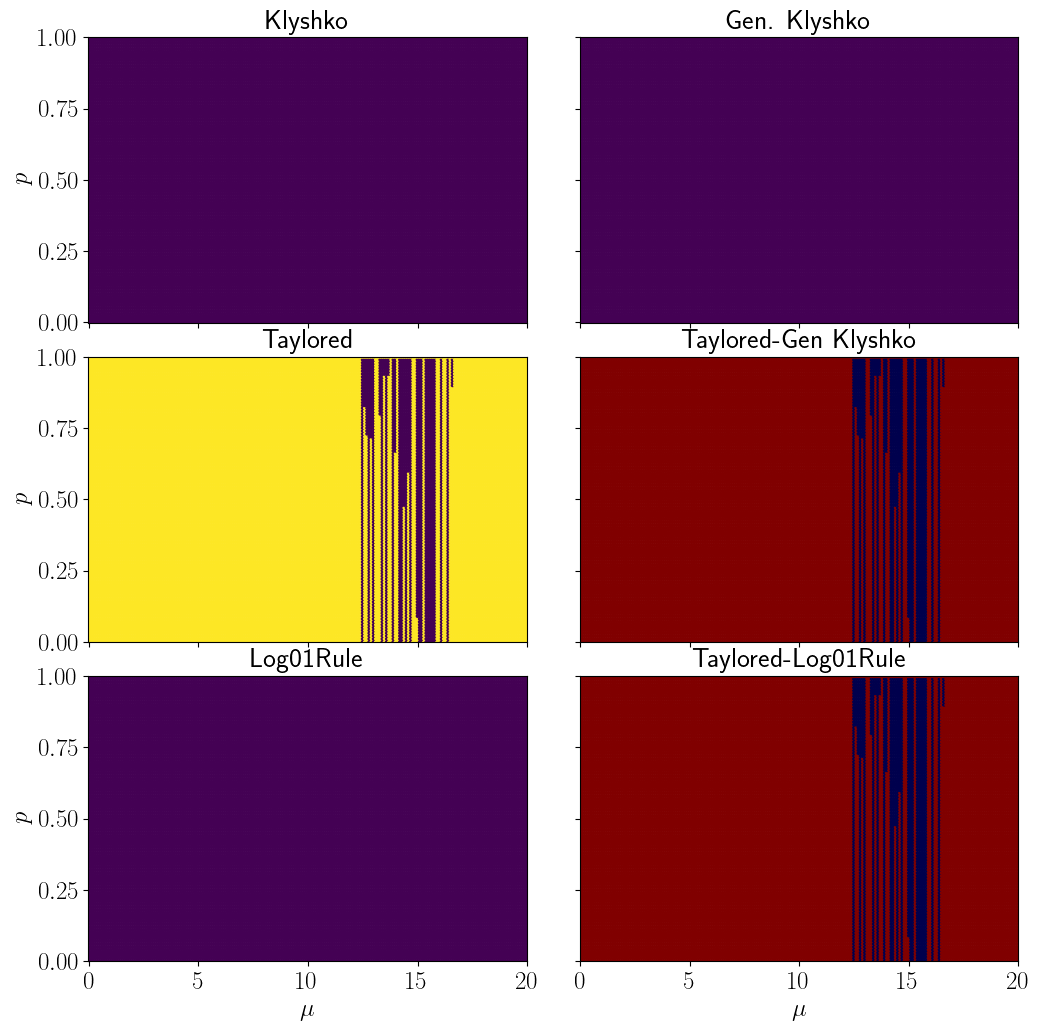

In [43]:
plt.rcParams['text.usetex'] = True
plt.rcParams.update({'font.size':18})

ncols=2
nrows=3

xmu, yp = np.meshgrid(mu_all, p_all)

fig, axs = plt.subplots(ncols=ncols, nrows=nrows,figsize=(12, 12),sharex='all', sharey='all')
plt.subplots_adjust(wspace=0.12, hspace=0.12)

levels=[0.0,1.0,2.0]
colors=['red','blue','black']
siz = 3.0

images = []
for ic in range(ncols):
    for ir in range(nrows):
        axs[ir,ic].set_xlim([-0.01,20])
        axs[ir,ic].set_ylim([-0.001,1])
#        axs[ic,ir].set_xticks([0,2,4,6,8,10])
#        axs[ic,ir].set_yticks([0,0.2,0.4,0.6,0.8,1])

axs[2,0].set_xlabel(r"$\mu$")
axs[2,1].set_xlabel(r"$\mu$")
axs[0,0].set_ylabel(r"$p$")
axs[1,0].set_ylabel(r"$p$")
axs[2,0].set_ylabel(r"$p$")
        
i=0

#col=axs[0].contourf(xmu, yp, nc_a_jj)
axs[0,0].scatter(xmu, yp, c=ac_kl,s=siz,marker="o")
axs[0,0].set_title(r'Klyshko',fontsize=20)

#col=axs[1].contourf(xmu, yp, nc_kl_jj)
axs[0,1].scatter(xmu, yp, c=ac_gkl,s=siz,marker="o")
axs[0,1].set_title(r'Gen. Klyshko',fontsize=20)


#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[1,0].scatter(xmu, yp, c=ac_tay,s=siz,marker="o")
axs[1,0].set_title(r'Taylored',fontsize=20)    

#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[1,1].scatter(xmu, yp, c=((ac_tay.astype(int)-ac_kl.astype(int))),s=siz,marker="o",cmap="seismic")
axs[1,1].set_title(r'Taylored-Gen Klyshko',fontsize=20)  

#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[2,0].scatter(xmu, yp, c=ac_log,s=siz,marker="o")
axs[2,0].set_title(r'Log01Rule',fontsize=20)    

#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[2,1].scatter(xmu, yp, c=((ac_tay.astype(int)-ac_log.astype(int))),s=siz,marker="o",cmap="seismic")
axs[2,1].set_title(r'Taylored-Log01Rule',fontsize=20)  

In [44]:
%%time

Np = 101
Nmu = 201

p_all= np.linspace(0.0001, 0.9999, num=Np, endpoint=True)
mu_all = np.linspace(0.0001, 20.0, num=Nmu, endpoint=True)

NP = 6
fi="../Data/All_analytical/BosonAdded_1/all_an_pba1_Np6.npy"

idx=np.arange(0,NP,1,dtype=int)
print(idx)
Nadd = 1
pps="5, Nadd =1"


noise_on = True

Pall=np.zeros((Np,Nmu,NP))

for ip in tqdm(range(Np)):
    for imu in range(Nmu):
        for iP in range(NP):
            Pall[ip,imu,iP] = pba_Pk_co_2_0(100,mu_all[imu],p_all[ip],iP,nad=1) #test_P_pba(mu_all[imu],p_all[ip],2,iP)

[0 1 2 3 4 5]


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 101/101 [19:19<00:00, 11.48s/it]

CPU times: user 51min 3s, sys: 6min 53s, total: 57min 56s
Wall time: 19min 19s


In [45]:
ac_gkl,ac_gkl_frac,ac_gkl_n = generalized_klyshko(Pall=Pall,indx=idx)

ac_gkl,ac_gkl_frac,ac_gkl_n = generalized_klyshko_first_Np(Pall=Pall,lof=list_of_files)

ac_kl,ac_kl_frac = klyshko(Pall=Pall)

ac_tay,ac_tay_frac = taylored(Pall=Pall)

ac_log,ac_log_frac = log01rule(Pall=Pall)

[0 1 2 3 4 5]


/tmp/ipykernel_572303/3489667697.py:30: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  Paux -= Pall[:,:,nn-1]*np.log((nn**nn/np.math.factorial(nn))*
/tmp/ipykernel_572303/3489667697.py:27: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  SumB += ((nn*Pall[:,:,nn]/Pall[:,:,nn-1])**k)/np.math.factorial(k)
/tmp/ipykernel_572303/2597303894.py:5: RuntimeWarning: divide by zero encountered in log
  Paux = Pall[:,:,1]+Pall[:,:,0]*np.log(Pall[:,:,0])
/tmp/ipykernel_572303/2597303894.py:5: RuntimeWarning: invalid value encountered in multiply
  Paux = Pall[:,:,1]+Pall[:,:,0]*np.log(Pall[:,:,0])


Text(0.5, 1.0, 'Taylored-Log01Rule')

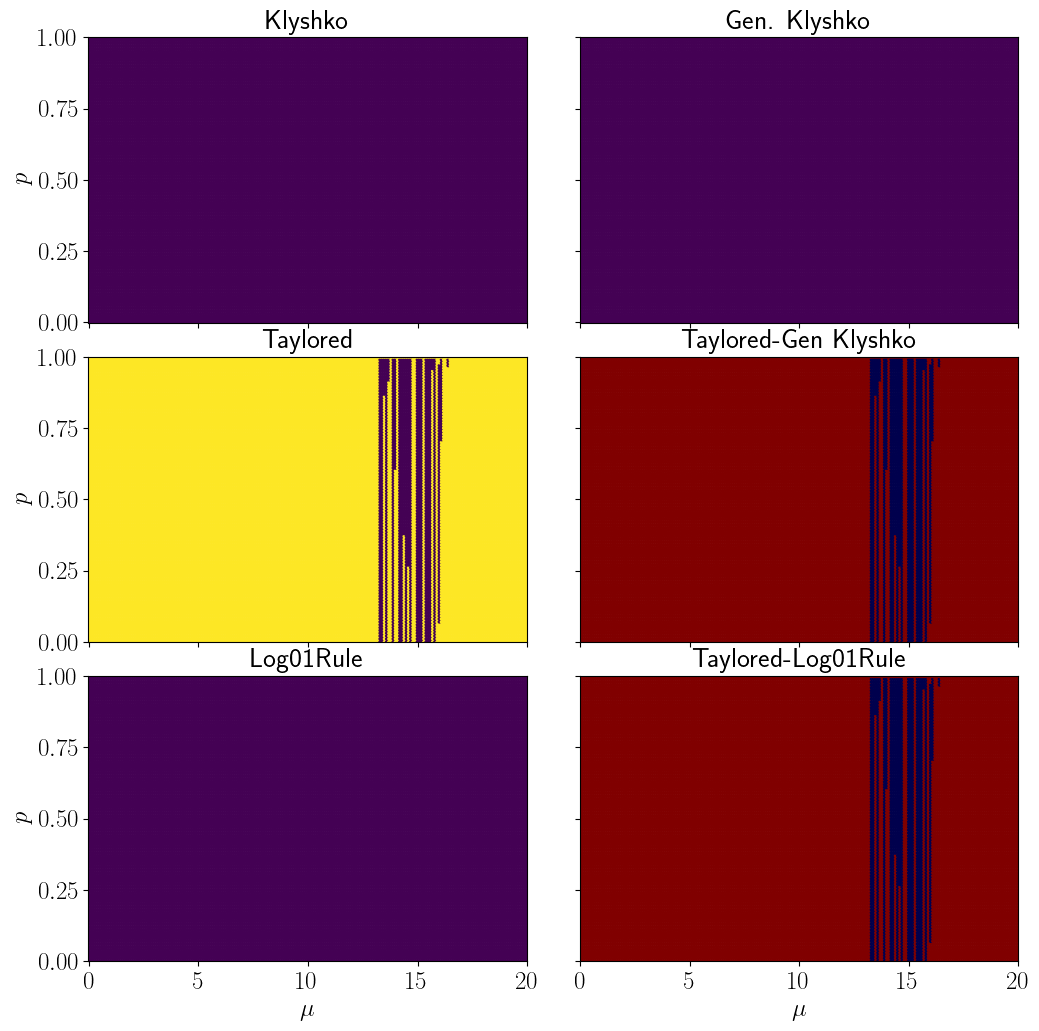

In [46]:
plt.rcParams['text.usetex'] = True
plt.rcParams.update({'font.size':18})

ncols=2
nrows=3

xmu, yp = np.meshgrid(mu_all, p_all)

fig, axs = plt.subplots(ncols=ncols, nrows=nrows,figsize=(12, 12),sharex='all', sharey='all')
plt.subplots_adjust(wspace=0.12, hspace=0.12)

levels=[0.0,1.0,2.0]
colors=['red','blue','black']
siz = 3.0

images = []
for ic in range(ncols):
    for ir in range(nrows):
        axs[ir,ic].set_xlim([-0.01,20])
        axs[ir,ic].set_ylim([-0.001,1])
#        axs[ic,ir].set_xticks([0,2,4,6,8,10])
#        axs[ic,ir].set_yticks([0,0.2,0.4,0.6,0.8,1])

axs[2,0].set_xlabel(r"$\mu$")
axs[2,1].set_xlabel(r"$\mu$")
axs[0,0].set_ylabel(r"$p$")
axs[1,0].set_ylabel(r"$p$")
axs[2,0].set_ylabel(r"$p$")
        
i=0

#col=axs[0].contourf(xmu, yp, nc_a_jj)
axs[0,0].scatter(xmu, yp, c=ac_kl,s=siz,marker="o")
axs[0,0].set_title(r'Klyshko',fontsize=20)

#col=axs[1].contourf(xmu, yp, nc_kl_jj)
axs[0,1].scatter(xmu, yp, c=ac_gkl,s=siz,marker="o")
axs[0,1].set_title(r'Gen. Klyshko',fontsize=20)


#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[1,0].scatter(xmu, yp, c=ac_tay,s=siz,marker="o")
axs[1,0].set_title(r'Taylored',fontsize=20)    

#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[1,1].scatter(xmu, yp, c=((ac_tay.astype(int)-ac_kl.astype(int))),s=siz,marker="o",cmap="seismic")
axs[1,1].set_title(r'Taylored-Gen Klyshko',fontsize=20)  

#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[2,0].scatter(xmu, yp, c=ac_log,s=siz,marker="o")
axs[2,0].set_title(r'Log01Rule',fontsize=20)    

#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[2,1].scatter(xmu, yp, c=((ac_tay.astype(int)-ac_log.astype(int))),s=siz,marker="o",cmap="seismic")
axs[2,1].set_title(r'Taylored-Log01Rule',fontsize=20) 

# General Tests

In [18]:
def generate_multiple_sets(M, N):
    # Generate (M x N-1) random numbers uniformly from (0, 1)
    random_numbers = np.random.uniform(0, 1, (M, N-1))
    
    # Sort each row
    random_numbers.sort(axis=1)
    
    # Add 0 at the beginning and 1 at the end for each row
    random_numbers = np.concatenate([np.zeros((M, 1)), random_numbers, np.ones((M, 1))], axis=1)
    
    # Compute the differences to get the N random numbers for each row
    random_numbers = np.diff(random_numbers, axis=1)
    
    # Scale each row by a random factor between 0 and 1
    scale_factors = np.random.uniform(0, 1, (M, 1))
    random_numbers *= scale_factors
    
    return random_numbers

In [19]:
N=10000
NP=8
Pall=np.empty((N,1,NP))
Pall[:,0,:]=generate_multiple_sets(N, NP)
idx=np.arange(0,NP,1,dtype=int)

In [20]:
#ac_gkl,ac_gkl_frac,ac_gkl_n = generalized_klyshko(Pall=Pall,indx=idx)
#print("GKL:",ac_gkl_frac)

ac_gkl,ac_gkl_frac,ac_gkl_n = generalized_klyshko_first_Np(Pall=Pall,lof=list_of_files)
print("GKL:",ac_gkl_frac)

ac_gklch,ac_gklch_frac,ac_gklch_n = generalized_klyshko_first_Np_ch(Pall=Pall,lof=list_of_files)
print("GKLch:",ac_gklch_frac)

ac_kl,ac_kl_frac = klyshko(Pall=Pall)
print("KL:",ac_kl_frac)

ac_tay,ac_tay_frac = taylored(Pall=Pall)
print("Kinf:",ac_tay_frac)

ac_log,ac_log_frac = log01rule(Pall=Pall)

print("LB:",ac_log_frac)

print(np.sum(np.abs(ac_gkl_frac-ac_tay_frac)))

[0 1 2 3 4 5 6 7]
GKL: 0.9999
[0 1 2 3 4 5 6 7]
GKLch: 0.5316
KL: 0.9999
Kinf: 0.9763
LB: 0.2042
0.023600000000000065


/tmp/ipykernel_482083/3489667697.py:30: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  Paux -= Pall[:,:,nn-1]*np.log((nn**nn/np.math.factorial(nn))*
/tmp/ipykernel_482083/3489667697.py:27: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  SumB += ((nn*Pall[:,:,nn]/Pall[:,:,nn-1])**k)/np.math.factorial(k)


# Numerics

### Optimization routines

In [47]:
def objf_no_fixation(probs=np.array([]),indx=np.array([],dtype=int),
                      fact=np.array([]),
                      initA=np.array([]),
                      initB=np.array([]),
                      initC=np.array([]),
                     bounds=[],bias=1e-8,tol=1e-6):
    
    #method='TNC'
    #method='Nelder-Mead'
    #method='SLSQP' #ok
    #method='trust-constr'
    objf = lambda x:fun_full(x,probs=probs,indx=indx,fact=fact)
        
    retA = minimize(objf, initA, method='Nelder-Mead',bounds=bounds,tol=tol)
    
    if(retA.fun >= 0):
        retB = minimize(objf, initB, method='Nelder-Mead',bounds=bounds,tol=tol)
    
        if(retB.fun >= 0):
            retC = minimize(objf, initC, method='Nelder-Mead',bounds=bounds,tol=tol)
            
            res=np.array([retA.fun,retB.fun,retC.fun])
            pos=[retA.x,retB.x,retC.x]
            
            imin = np.argmin(res)
            
            ret = res[imin]
            init = pos[imin]
                
        else:
            ret = retB.fun
            init = retB.x
        
    else:
        ret = retA.fun
        init = retA.x
    
    return -ret,init

In [48]:
def objf_fixation(probs=np.array([]),indx=np.array([],dtype=int),
                      fact=np.array([]),
                      initA=np.array([]),
                      bounds=[],bias=1e-8,tol=1e-6,
                      lam_fix=1.0,i_fix=0):
    
    objf = lambda x:fun_fix_one(x,probs=probs,indx=indx,
                                  fact=fact,lam_fix=lam_fix,i_fix=i_fix)
        
    retA = minimize(objf, initA, method='Nelder-Mead',bounds=bounds,tol=tol)

    ret = retA.fun
    init = retA.x
    
    return -ret,init

In [49]:
def fun_full(lam,probs=np.array([]),
                      indx=np.array([],dtype=int),fact=np.array([])):
    
    prah = maxPrahfun(indx=indx,lam=lam,fact=fact)
    
    ret = prah - np.dot(lam,probs)
    
    return ret

In [50]:
def fun_fix_one(lam,probs=np.array([]),
                indx=np.array([],dtype=int),
                fact=np.array([]),
                lam_fix=1.0,i_fix=0):
    
    lam_all = np.insert(lam,i_fix,lam_fix)
    prah = maxPrahfun(indx=indx,lam=lam_all,fact=fact)
    
    ret = prah - np.dot(lam_all,probs)
    
    return ret

In [51]:
def maxPrahfun(indx=np.array([]),lam=np.array([]),fact=np.array([])):
    
    mxin = np.amax(indx)

    lam_aux = np.zeros(mxin+2)
    lam_aux[indx]=lam
    
    coef = (lam_aux[1:mxin+2]-lam_aux[0:mxin+1])*fact
    
    p = Polynomial(coef)
    all_roots = p.roots()
    
    real_roots = np.real(all_roots)
    real_roots = np.append(real_roots[real_roots>0],0.0)
    
    coef = lam_aux[0:mxin+1]*fact
    p2 = Polynomial(coef)
    
    val = np.amax(p2(real_roots)*np.exp(-real_roots))
    prah = np.maximum(0.0,val)
    
    return prah

In [52]:
def numcrit2D(nc_a=np.array([]),NP=NP,bias=1e-7,tol=1e-7,Pall=np.ones((10,10,3))):

    nc_n = np.copy(nc_a)
    
    
    ineg = np.array(np.where(nc_n==False))
    
    Nn = ineg.shape[1]
    print(Nn,ineg.shape)


    lam_mem = np.zeros((*nc_n.shape,NP))
    loss_mem = np.zeros(nc_n.shape)

    initA = np.zeros(NP)
    initB = np.ones(NP)
    initC = 0.10-0.2*np.random.rand(NP)
    
    Ns = np.prod(np.array([*nc_n.shape]))
    
    bound=(-1.0,1.0)
    bounds=[]
    for i in range(NP):
        bounds.append(bound)
    

    indx_all=np.array(range(NP))
    fact = np.array([1.0/factorial(i1) for i1 in range(np.max(indx_all)+1)])

    for iN in tqdm(range(Nn)): 
        iNN = ineg[:,iN]
    #for iN in tqdm(range(Ns)):
        Pin=Pall[iNN[0],iNN[1],:]

        loss,initA = objf_no_fixation(probs=Pin,indx=indx_all,
                           fact=fact,
                           initA=initA,
                           initB=initB,
                           initC=initC,
                           bounds=bounds,bias=bias,tol=tol)
                 
        if(loss > bias):
            nc_n[iNN[0],iNN[1]] = True
            initA=initA/np.max(np.abs(initA))
            lam_mem[iNN[0],iNN[1],:] = initA
            initB = np.copy(initA)
        else:
            initA = np.copy(initB) 
            initB = -initB
            
        loss_mem[iNN[0],iNN[1]] = loss
            
    ncnf = np.sum(nc_n.astype(int))/Ns
    return nc_n,ncnf,loss_mem,lam_mem

In [53]:
def numcrit2D_fix(nc_a=np.array([]),NP=NP,bias=1e-7,tol=1e-7,Pall=np.ones((10,10,3))):

    nc_n = np.copy(nc_a)
    
    
    ineg = np.array(np.where(nc_n==False))
    
    Nn = ineg.shape[1]
    print(Nn,ineg.shape)


    lam_mem = np.zeros((*nc_n.shape,NP))
    loss_mem = np.zeros(nc_n.shape)
    
    Ns = np.prod(np.array([*nc_n.shape]))
    
    bound=(-1.0,1.0)
    bounds=[]
    for i in range(NP-1):
        bounds.append(bound)
    
    indx_all=np.array(range(NP))
    
    fact = np.array([1.0/factorial(i1) for i1 in range(np.max(indx_all)+1)])

    for iN in tqdm(range(Nn)):
        
        initA = 0.1*(0.5-np.random.rand(NP-1))
        
        iNN = ineg[:,iN]
        Pin=Pall[iNN[0],iNN[1],:]
        
        for i_fix in range(NP):
            
            loss,initB = objf_fixation(probs=Pin,indx=indx_all,
                                       fact=fact,
                                       initA=initA,
                                       bounds=bounds,bias=bias,tol=tol,
                                       lam_fix=1.0,i_fix=i_fix)     
            if(loss > bias):
                nc_n[iNN[0],iNN[1]] = True
                lam_mem[iNN[0],iNN[1],:] = np.insert(initB,i_fix,1.0)
                loss_mem[iNN[0],iNN[1]] = loss
                break
            else:
                loss,initB = objf_fixation(probs=Pin,indx=indx_all,
                                       fact=fact,
                                       initA=initA,
                                       bounds=bounds,bias=bias,tol=tol,
                                       lam_fix=-1.0,i_fix=i_fix) 
                    
                if(loss > bias):
                    nc_n[iNN[0],iNN[1]] = True
                    lam_mem[iNN[0],iNN[1],:] = np.insert(initB,i_fix,-1.0)
                    loss_mem[iNN[0],iNN[1]] = loss
                    break       
    ncnf = np.sum(nc_n.astype(int))/Ns
    return nc_n,ncnf,loss_mem,lam_mem

In [54]:
def collect_lam(loss_mem,lam_mem,xp,yp,delta=1e-6):
    
    Nx,Ny,Np = lam_mem.shape[0],lam_mem.shape[1],lam_mem.shape[2]
    
    indices = np.where(loss_mem > delta)
    lam = np.empty((len(indices[0]), 2 + Np))

    for idx in range(len(indices[0])):
        i, j = indices[1][idx], indices[0][idx]
        lam[idx, :2] = [xp[i], yp[j]]  # store the indices
        lam[idx, 2:] = lam_mem[i, j, :]  # store the vector
        
    return lam

In [55]:
def analcrit2D(Pall=np.ones((10,10,3))):

    Psh = Pall.shape
    Ns = np.array(np.prod(Psh[0:-1]))
    
    Np = Psh[-1]
    Nm = Np-1
    
    
    nonclass = np.zeros((Psh[0],Psh[1]), dtype=bool)

    ac_kl,ac_kl_frac = klyshko(Pall=Pall)
    nonclass = np.where(ac_kl > 0,True,nonclass)
    
    ac_tay,ac_tay_frac = taylored(Pall=Pall)
    
    nonclass = np.where(ac_tay > 0,True,nonclass)
    
    ac_log,ac_log_frac = log01rule(Pall=Pall)
    
    nonclass = np.where(ac_log > 0,True,nonclass)
        
    ncaf = np.sum(nonclass.astype(int))/Ns
    return nonclass,ncaf

In [61]:
%%time

Np = 51
Nmu = 81

p_all= np.linspace(0.0001, 0.9999, num=Np, endpoint=True)
mu_all = np.linspace(0.0001, 20.0, num=Nmu, endpoint=True)

NP = 6
#fi="../Data/Numerical/BosonAdded_2/all_pba2_NP6.npy"
fi="../Data/Numerical/BosonAdded_2/test.npy"

idx=np.arange(0,NP,1,dtype=int)
print(idx)
Nadd = 1
pps="5, Nadd =1"


noise_on = True

Pall=np.zeros((Np,Nmu,NP))

for ip in range(Np):
    for imu in range(Nmu):
        for iP in range(NP):
            #Pall[ip,imu,iP] = test_P_pba_v2(mu_all[imu],p_all[ip],2,iP)
            Pall[ip,imu,iP] = pba_Pk_co_2_3(100,mu_all[imu],p_all[ip],iP,nad=1) #test_P_pba(mu_all[imu],p_all[ip],2,iP)

[0 1 2 3 4 5]
CPU times: user 10min 1s, sys: 1min 20s, total: 11min 22s
Wall time: 3min 47s


In [62]:

ac_all,ac_all_frac = analcrit2D(Pall=Pall)

nc_n_in = (np.copy(ac_all))


nc_n,nc_frac,loss_mem_jj,nc_n_lambdas = numcrit2D(nc_a=nc_n_in,NP=NP,bias=1e-7,tol=1e-8,
                                        Pall=Pall)

nc_n_in = (np.copy(nc_n))

nc_n_fix,nc_frac_fix,loss_mem_jj,nc_n_lambdas = numcrit2D_fix(nc_a=nc_n_in,NP=NP,bias=1e-7,tol=1e-8,
                                        Pall=Pall)

/tmp/ipykernel_572303/3489667697.py:30: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  Paux -= Pall[:,:,nn-1]*np.log((nn**nn/np.math.factorial(nn))*
/tmp/ipykernel_572303/3489667697.py:31: RuntimeWarning: divide by zero encountered in divide
  ((Pall[:,:,nn]**(nn-1))/(Pall[:,:,nn-1]**nn))*
/tmp/ipykernel_572303/3489667697.py:30: RuntimeWarning: invalid value encountered in multiply
  Paux -= Pall[:,:,nn-1]*np.log((nn**nn/np.math.factorial(nn))*
/tmp/ipykernel_572303/3489667697.py:27: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  SumB += ((nn*Pall[:,:,nn]/Pall[:,:,nn-1])**k)/np.math.factorial(k)
/tmp/ipykernel_572303/2597303894.py:5: RuntimeWarning: divide by zero encountered in log
  Paux = Pall[:,:,1]+Pall[:,:,0]*np.log(Pall[:,:,0])
/tmp/ipykernel_572303/2597303894.

0 (2, 0)


0it [00:00, ?it/s]


0 (2, 0)


0it [00:00, ?it/s]


In [63]:
with open(fi, 'wb') as f:
    np.save(f,p_all)
    np.save(f,mu_all)
    np.save(f,Pall)  
    np.save(f,ac_all)
    np.save(f,nc_n)
    np.save(f,nc_n_fix)
    

Text(0.5, 1.0, 'A-N')

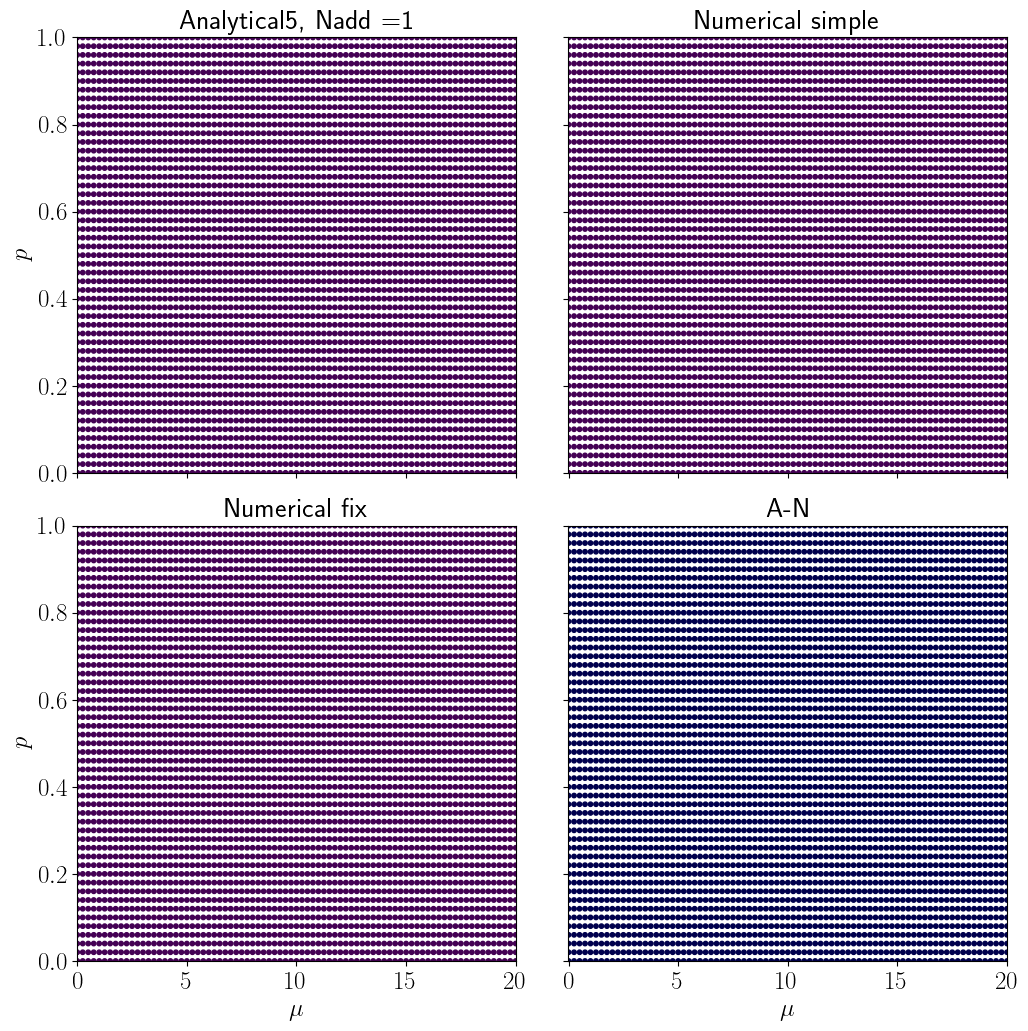

In [64]:
xmu, yp = np.meshgrid(mu_all, p_all)

plt.rcParams['text.usetex'] = True
plt.rcParams.update({'font.size':18})

ncols=2
nrows=2

#ncols=2
#nrows=2

fig, axs = plt.subplots(ncols=ncols, nrows=nrows,figsize=(12, 12),sharex='all', sharey='all')
plt.subplots_adjust(wspace=0.12, hspace=0.12)

levels=[0.0,1.0,2.0]
colors=['red','blue','black']
siz = 10.0

images = []
for ic in range(ncols):
    for ir in range(nrows):
        axs[ir,ic].set_xlim([-0.01,20])
        axs[ir,ic].set_ylim([-0.001,1])
#        axs[ic,ir].set_xticks([0,2,4,6,8,10])
#        axs[ic,ir].set_yticks([0,0.2,0.4,0.6,0.8,1])

axs[1,0].set_xlabel(r"$\mu$")
axs[1,1].set_xlabel(r"$\mu$")
axs[0,0].set_ylabel(r"$p$")
axs[1,0].set_ylabel(r"$p$")
axs[1,0].set_ylabel(r"$p$")
        
i=0

#col=axs[0].contourf(xmu, yp, nc_a_jj)
axs[0,0].scatter(xmu, yp, c=ac_all,s=siz,marker="o")
axs[0,0].set_title(r'Analytical'+ pps,fontsize=20)

#col=axs[1].contourf(xmu, yp, nc_kl_jj)
axs[0,1].scatter(xmu, yp, c=nc_n,s=siz,marker="o")
axs[0,1].set_title(r'Numerical simple',fontsize=20)


#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[1,0].scatter(xmu, yp, c=nc_n_fix,s=siz,marker="o")
axs[1,0].set_title(r'Numerical fix',fontsize=20)    

#col=axs[2].contourf(xmu, yp, nc_klp_jj)
axs[1,1].scatter(xmu, yp, c=((nc_n_fix.astype(int)-nc_n.astype(int))),s=siz,marker="o",cmap="seismic")
axs[1,1].set_title(r'A-N',fontsize=20) 

In [90]:
fi="../Data/Numerical/BosonAdded_1/all_pba1_NP4.npy"

def run(NP=6,fi="test.npy"):
    Np = 15
    Nmu = 15

    p_all= np.linspace(0.0001, 0.9999, num=Np, endpoint=True)
    mu_all = np.linspace(0.0001, 10.0, num=Nmu, endpoint=True)


    idx=np.arange(0,NP,1,dtype=int)

    noise_on = True

    Pall=np.zeros((Np,Nmu,NP))

    for ip in range(Np):
        for imu in range(Nmu):
            for iP in range(NP):
                Pall[ip,imu,iP] = test_P_pba_v2(mu_all[imu],p_all[ip],2,iP)
                
    ac_all,ac_all_frac = analcrit2D(Pall=Pall)

    nc_n_in = (np.copy(ac_all))


    nc_n,nc_frac,loss_mem_jj,nc_n_lambdas = numcrit2D(nc_a=nc_n_in,NP=NP,bias=1e-7,tol=1e-8,
                                        Pall=Pall)

    num_lam = collect_lam(loss_mem_jj,nc_n_lambdas,mu_all,p_all,delta=1e-7)
    
    nc_n_in = (np.copy(nc_n))

    nc_n_fix,nc_frac_fix,loss_mem_jj,nc_n_lambdas = numcrit2D_fix(nc_a=nc_n_in,NP=NP,bias=1e-7,tol=1e-8,
                                        Pall=Pall)
    
    num_lam_fix = collect_lam(loss_mem_jj,nc_n_lambdas,mu_all,p_all,delta=1e-7)
    
    with open(fi, 'wb') as f:
        np.save(f,p_all)
        np.save(f,mu_all)
        np.save(f,Pall)  
        np.save(f,ac_all)
        np.save(f,nc_n)
        np.save(f,nc_n_fix)
        np.save(f,num_lam)
        np.save(f,num_lam_fix)
        
    return num_lam, num_lam_fix
        

In [91]:
fi="../Data/Numerical/BosonAdded_2/all_pba2_NP4_test.npy"
lam,lam_fix = run(NP=4,fi=fi)

/tmp/ipykernel_482083/3489667697.py:30: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  Paux -= Pall[:,:,nn-1]*np.log((nn**nn/np.math.factorial(nn))*
/tmp/ipykernel_482083/3489667697.py:27: DeprecationWarning: `np.math` is a deprecated alias for the standard library `math` module (Deprecated Numpy 1.25). Replace usages of `np.math` with `math`
  SumB += ((nn*Pall[:,:,nn]/Pall[:,:,nn-1])**k)/np.math.factorial(k)


176 (2, 176)


100%|█████████████████████████████████████████| 176/176 [00:41<00:00,  4.26it/s]


66 (2, 66)


100%|███████████████████████████████████████████| 66/66 [00:37<00:00,  1.76it/s]


In [92]:
with open(fi, 'rb') as f:
    p_all=np.load(f)
    mu_all=np.load(f)
    Pall=np.load(f)  
    ac_all=np.load(f)
    nc_n=np.load(f)
    nc_n_fix=np.load(f)
    num_lam=np.load(f)
    num_lam_fix=np.load(f)

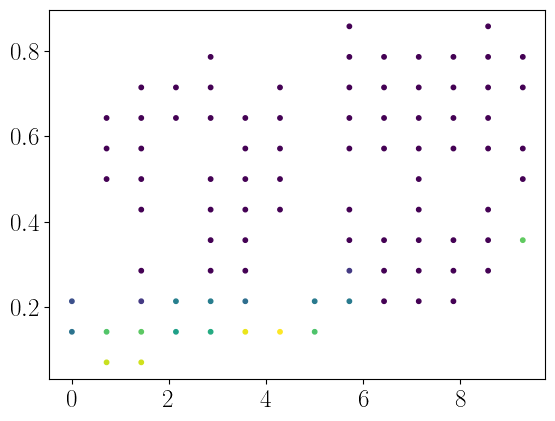

In [69]:
plt.scatter(num_lam[:,0], num_lam[:,1],c=num_lam[:,2],s=siz,marker="o")
#plt.scatter(lam_fix[:,0], lam_fix[:,1],c=lam_fix[:,2],s=siz,marker="s")

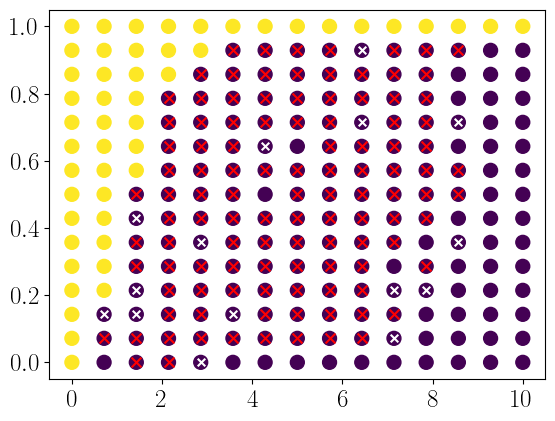

In [93]:
xmu, yp = np.meshgrid(mu_all, p_all)
plt.scatter(xmu, yp, c=ac_all,marker="o",s=100)
plt.scatter(num_lam[:,0], num_lam[:,1],c="red",s=50,marker="x")
plt.scatter(num_lam_fix[:,0], num_lam_fix[:,1],c="white",s=30,marker="x")

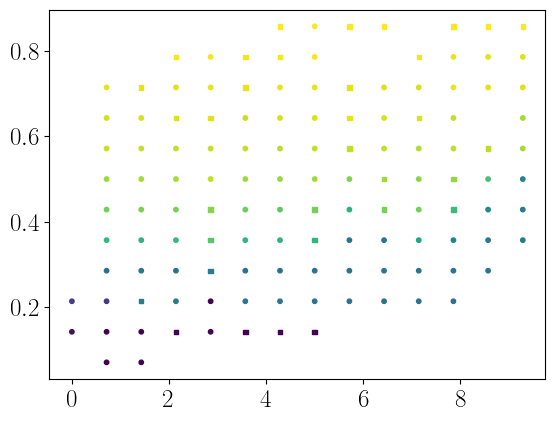

In [38]:
plt.scatter(lam[:,0], lam[:,1],c=lam[:,4],s=siz,marker="o")
plt.scatter(lam_fix[:,0], lam_fix[:,1],c=lam_fix[:,4],s=siz,marker="s")

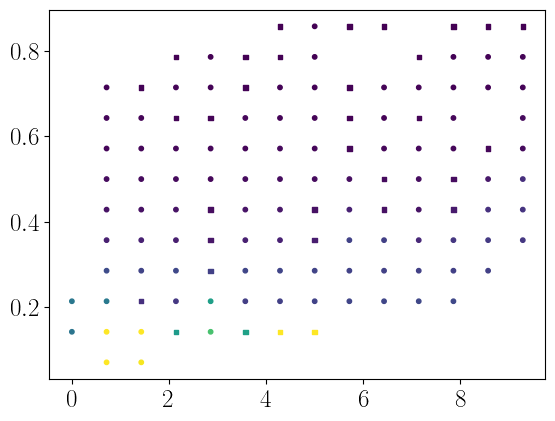

In [39]:
plt.scatter(lam[:,0], lam[:,1],c=lam[:,5],s=siz,marker="o")
plt.scatter(lam_fix[:,0], lam_fix[:,1],c=lam_fix[:,5],s=siz,marker="s")

In [126]:
print(num_lam[:,2:])

[[ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [-0.07107563  0.65019926 -1.          1.        ]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [-0.14048058  0.76654388 -1.          0.99915384]
 [ 0.          0.          0.          0.        ]
 [-0.11629105  0.73403722 -0.97403001  1.        ]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [-1.          1.         -0.6156677   0.16391029]
 [-0.57251769  0.99950555 -1.  

In [109]:
Paux=np.zeros(4)
for iP in range(4):
    Paux[iP]=test_P_pba_v2(2.14293571,0.21434286,2,iP)

In [124]:
print(Paux)
print(num_lam[18,2:])
print(Paux/lam[18,2:])

[0.0921654  0.19750452 0.21493612 0.17248278]
[-1.          1.         -0.6156677   0.16391029]
[-0.0921654   0.19750452 -0.3491106   1.05229993]


In [120]:
(-0.0921654+0.1975)/0.214936

0.49007425466185295

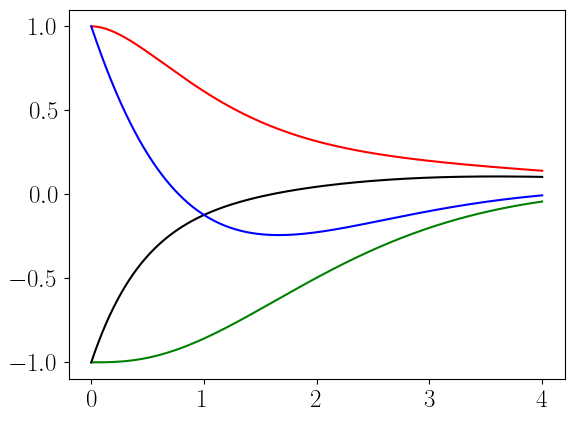

In [144]:
plt.plot(x,(1+x-0.5*x**2*(1-x/3))*np.exp(-x),c="red")
plt.plot(x,(-1-x-0.5*x**2*(1-x/3))*np.exp(-x),c="green")
plt.plot(x,(-1+x-0.5*x**2*(1-x/3))*np.exp(-x),c="black")
plt.plot(x,(1-x-0.5*x**2*(1-x/3))*np.exp(-x),c="blue")